In [1]:
%pip install matplotlib networkx

  Using cached networkx-3.7-py3-none-any.whl.metadata (6.7 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 307.5 kB/s  0:00:07a 0:00:010:00:02:04
Note: you may need to restart the kernel to use updated packages.


--- Results ---
Coloring assignments: {1: 0, 2: 1, 9: 2, 8: 0, 0: 2, 3: 1, 6: 3, 7: 3, 5: 2, 4: 0}
Is valid: True
Chromatic number used (k): 4


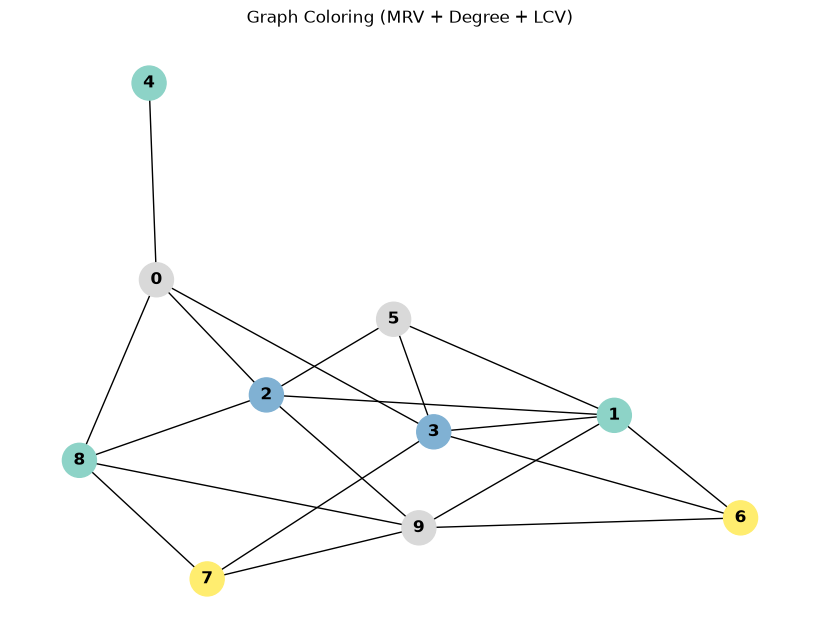

In [ ]:
import matplotlib.pyplot as plt
import networkx as nx
import random


def is_valid_coloring(graph, coloring):
  for u, v in graph.edges():
    if coloring[u] == coloring[v]:
      return False
  return True


def get_available_colors(graph, node, coloring, color_pool):
  neighbor_colors = {
      coloring[nbr] for nbr in graph.neighbors(node) if nbr in coloring
  }
  return [c for c in color_pool if c not in neighbor_colors]


def select_mrv_degree_node(graph, coloring, color_pool):
  
  uncolored_nodes = [node for node in graph.nodes() if node not in coloring]

  best_node = None
  min_remaining = float("inf")
  max_uncolored_degree = -1

  for node in uncolored_nodes:
    remaining_count = len(
        get_available_colors(graph, node, coloring, color_pool)
    )
    uncolored_degree = sum(
        1 for nbr in graph.neighbors(node) if nbr not in coloring
    )

    if (
        remaining_count < min_remaining
        or (
            remaining_count == min_remaining
            and uncolored_degree > max_uncolored_degree
        )
    ):
      min_remaining = remaining_count
      max_uncolored_degree = uncolored_degree
      best_node = node

  return best_node


def select_lcv_color(graph, node, coloring, color_pool):
 
  available_colors = get_available_colors(graph, node, coloring, color_pool)
  uncolored_neighbors = [
      nbr for nbr in graph.neighbors(node) if nbr not in coloring
  ]

  def lcv_cost(color):
    conflicts_caused = 0
    for nbr in uncolored_neighbors:
      nbr_available = get_available_colors(graph, nbr, coloring, color_pool)
      if color in nbr_available:
        conflicts_caused += 1
    return conflicts_caused

  sorted_colors = sorted(available_colors, key=lambda c: (lcv_cost(c), c))
  return sorted_colors[0]


def mrv_degree_lcv_coloring(graph):
  coloring = {}
  total_nodes = graph.number_of_nodes()

  while len(coloring) < total_nodes:
    used_colors = set(coloring.values())
    max_c = max(used_colors) if used_colors else -1
    color_pool = list(range(max_c + 2))

    node = select_mrv_degree_node(graph, coloring, color_pool)

    chosen_color = select_lcv_color(graph, node, coloring, color_pool)
    coloring[node] = chosen_color

  return coloring


n_nodes = 10
p = 0.35
g = nx.erdos_renyi_graph(n=n_nodes, p=p, seed=42)

coloring_result = mrv_degree_lcv_coloring(g)

print("--- Results ---")
print("Coloring assignments:", coloring_result)
print("Is valid:", is_valid_coloring(g, coloring_result))
print("Chromatic number used (k):", len(set(coloring_result.values())))

color_map = [coloring_result[node] for node in g.nodes()]
pos = nx.spring_layout(g, seed=42)

plt.figure(figsize=(8, 6))
nx.draw(
    g,
    pos,
    node_color=color_map,
    cmap=plt.cm.Set3,
    with_labels=True,
    node_size=600,
    font_weight="bold",
)
plt.title("Graph Coloring (MRV + Degree + LCV)")
plt.show()